**Human Movement Intelligence | Biomechanical Load Estimation | Presented by: Reza Saadatyar (2026)**

**01 | Original Dataset Audit and Trial Registry**

![Original Essex dataset audit and trial registry, with wearable IMU placements and original source provenance](../../images/01_consolidated_workflow.svg)

**Research question:** Are the original six-activity Essex source files authentic, participant-linked and traceable to unique movement records and original trial identifiers?

**Published source:** Hollinger et al. (2026), *Scientific Data*, [DOI 10.1038/s41597-026-07429-3](https://doi.org/10.1038/s41597-026-07429-3); [Figshare 30225739, version 13](https://doi.org/10.6084/m9.figshare.30225739.v13). This is the original full MATLAB dataset, not the separate 444-record BoneNet derivative.

**Research sequence:** Source identity and checksum → safe ZIP extraction → 40 original participant files → MATLAB Data fields and FE representations → workbook subject reconciliation → 1,897 original movement trials → activity/source coverage → integrated scientific Quality Gate.

**Recorded study results:** 40 MAT files, 1,897 source Data elements, 1,897 readable UpdatedTrialID values, 168 source-empty FE fields and 1,729 opaque/structured FE fields. The last saved run reported a PASSED source/trial gate. The revised Quality Gate now supports an independent archive-fingerprint check and requires re-execution.

**Scope and reproducibility:** Original record identifiers are preserved. Physical IMU/FE units, decoded strain waveforms, temporal alignment, clinical use and subject-independent regression are separate research questions. Original Notebooks 01/02 are preserved in Git history; their results are not overwritten; new files are saved directly in `output/`. Five names overlapping original Stage 01 files use the distinct `01_dataset_*` prefix to avoid accidental replacement.


**00. Colab Repository Setup**


In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
repo_url = "https://github.com/RezaSaadatyar/human-movement-intelligence.git"
repo_path = Path("/content") / repo_url.split("/")[-1].removesuffix(".git")

%cd /content

if not repo_path.exists():
    !git clone -q {repo_url}

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content
/content/human-movement-intelligence


**01. Imports and Environment**


In [2]:
# ======================== 01. Imports and Environment ========================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("biomechanical_load_estimation")

# ---------------------------- 2. Standard Library ----------------------------
import json
from pathlib import Path
from zipfile import ZIP_DEFLATED, ZipFile

# ----------------- 3. Scientific Computing and Data Analysis -----------------
import pandas as pd

# ------------------- 4. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure
plot_style(font_family="DejaVu Sans", title_size=12.5, title_weight="normal",
    label_size=11.5, label_weight="normal", tick_size=11, legend_size=10,
    figure_dpi=100, figure_size=(9, 4))

# ------------------ 5. Shared and Study Research Utilities -------------------
from core.output_download import download_outputs_from_colab
from essex_output_layout import flatten_legacy_output_folders
from essex_figshare import (
    ARTICLE_ID, ARTICLE_VERSION, fetch_version_manifest,
    find_published_file, ensure_source_file, inspect_matlab_archive,
    extract_matlab_files, inspect_subject_mat,
)
from essex_record_audit import (
    audit_workbook_ids, audit_mat_records, summarise_trial_evidence,
)

# ---------------------- 6. Source and Output Locations -----------------------
raw_dir = root / "data" / "raw" / "essex_femoral_neck_loading"
mat_dir = raw_dir / "matlab_records"
historical_output_dir = root / "biomechanical_load_estimation" / "output"
output_dir = historical_output_dir
raw_dir.mkdir(parents=True, exist_ok=True)
output_dir.mkdir(parents=True, exist_ok=True)
assert output_dir.name == "output"
migration = flatten_legacy_output_folders(output_dir)
if any(migration.values()):
    print("Previous nested research outputs flattened:", migration)
print("Figshare article:", ARTICLE_ID, "| version:", ARTICLE_VERSION)
print("Research outputs saved directly to:", output_dir)


Figshare article: 30225739 | version: 13
Research outputs saved directly to: /content/human-movement-intelligence/biomechanical_load_estimation/output


**02. Official Figshare Source Manifest**

Read the version-pinned published article, file IDs, original download names, sizes, licence and published hashes. The actual archive integrity is checked independently in the next section.


In [3]:
# =================== 02. Official Figshare Source Manifest ===================

# ------------------- 1. Retrieve Official Version Metadata -------------------
article, source_files = fetch_version_manifest()
archive_file = find_published_file(source_files, "MATLAB.zip")
source_table = pd.DataFrame([
    {
        "file_id": item.get("id"),
        "filename": item.get("name"),
        "size_bytes": item.get("size"),
        "download_url": item.get("download_url"),
        "published_md5": item.get("computed_md5") or item.get("supplied_md5"),
    }
    for item in source_files
])
display(source_table)

# -------------------- 2. Record Original Dataset Identity --------------------
metadata = {
    "article_id": ARTICLE_ID,
    "version": ARTICLE_VERSION,
    "title": article.get("title"),
    "doi": article.get("doi"),
    "published_date": article.get("published_date"),
    "license": article.get("license"),
    "archive_file_id": archive_file["id"],
    "archive_filename": archive_file["name"],
    "archive_size_bytes": archive_file["size"],
    "archive_published_md5": archive_file.get("computed_md5") or archive_file.get("supplied_md5"),
}
source_table.to_csv(output_dir / "01_dataset_figshare_file_manifest.csv", index=False)
print("Article:", metadata["title"])
print("Pinned archive:", metadata["archive_filename"])
print("Archive size (MiB):", round(metadata["archive_size_bytes"] / 1024**2, 2))


,file_id,filename,size_bytes,download_url,published_md5
0,63190519,OpenSim.zip,10904670,https://ndownloader.figshare.com/files/63190519,a1d002db6f1d77eef9c0fe3d5f8ea78f
1,63190690,MATLAB.zip,235590610,https://ndownloader.figshare.com/files/63190690,1b1c94eb552ba11f1c5521ec9ef49b96
2,63341380,Visual3D.zip,19308519333,https://ndownloader.figshare.com/files/63341380,de426331d951f1ed52feb0713700f837
3,63342400,SubCharacteristics.xlsx,29700,https://ndownloader.figshare.com/files/63342400,cbd5ebc13efca8efbba0dd644e5056ef
4,63342406,angles.xlsx,31175261,https://ndownloader.figshare.com/files/63342406,3a695d26a6d67f0f682628ed7b2911c2
5,63343417,README.md,7728,https://ndownloader.figshare.com/files/63343417,a43306a8db24a33b55ade29421bb628c


Article: Dataset for Rapid Estimation of Femoral Neck Loading During Gait and Dynamic Exercises
Pinned archive: MATLAB.zip
Archive size (MiB): 224.68


**03. Source Archive and ZIP Integrity**

Verify the official source archive using published file metadata and local SHA256, inspect ZIP structure and CRC, and prevent unsafe extraction.


In [4]:
# =================== 03. Source Archive and ZIP Integrity ====================

# --------------- 1. Download and Verify Official Source Bytes ----------------
archive_path, archive_hashes = ensure_source_file(archive_file, raw_dir)
print("Archive:", archive_path)
print("Verified local SHA256:", archive_hashes["sha256"])

# --------------------- 2. Validate the Complete Archive ----------------------
zip_records = inspect_matlab_archive(archive_path, expected_mat_files=40)
archive_table = pd.DataFrame(zip_records)
display(archive_table.head(10))
archive_table.to_csv(output_dir / "01_dataset_matlab_archive_inventory.csv", index=False)
print("Verified MATLAB files:", int(archive_table["is_matlab_file"].sum()))
print("Total uncompressed MiB:", round(archive_table["size_bytes"].sum() / 1024**2, 2))


Archive: /content/human-movement-intelligence/data/raw/essex_femoral_neck_loading/MATLAB.zip
Verified local SHA256: c50f10d1364686412b7ab64cac435dc85864dc8dbb34d2804b9cf37f2e29132d


,filename,size_bytes,compressed_bytes,is_matlab_file
0,MATLAB/,0,0,False
1,MATLAB/Processed Data/,0,0,False
2,MATLAB/Processed Data/subj04.mat,5950822,5947433,True
3,MATLAB/Processed Data/subj05.mat,5952359,5949100,True
4,MATLAB/Processed Data/subj06.mat,5960044,5956881,True
5,MATLAB/Processed Data/subj08.mat,5947583,5944209,True
6,MATLAB/Processed Data/subj09.mat,5218815,5215844,True
7,MATLAB/Processed Data/subj10.mat,5968410,5964994,True
8,MATLAB/Processed Data/subj11.mat,4980060,4977585,True
9,MATLAB/Processed Data/subj12.mat,5841830,5838897,True


Verified MATLAB files: 40
Total uncompressed MiB: 224.79


**04. Original Participant File Inventory**

Extract the 40 published participant MAT files and preserve their authentic, nonconsecutive identifiers. Check source file integrity and inventory.


In [5]:
# ================== 04. Original Participant File Inventory ==================

# -------------------- 1. Extract Validated MATLAB Members --------------------
mat_paths = extract_matlab_files(archive_path, mat_dir, zip_records)
participant_ids = [path.stem.lower() for path in mat_paths]
assert len(mat_paths) == len(set(participant_ids)) == 40
assert all(path.stat().st_size > 0 for path in mat_paths)

# ------------------- 2. Inspect Explicit Source Filenames --------------------
participant_table = pd.DataFrame({
    "source_file": [path.name for path in mat_paths],
    "subject_id": participant_ids,
    "file_size_bytes": [path.stat().st_size for path in mat_paths],
})
display(participant_table)
participant_table.to_csv(output_dir / "01_dataset_matlab_participant_inventory.csv", index=False)
print("Independent source files:", len(participant_table))
print("IDs are observed from filenames, not generated by range.")


,source_file,subject_id,file_size_bytes
0,subj04.mat,subj04,5950822
1,subj05.mat,subj05,5952359
2,subj06.mat,subj06,5960044
3,subj08.mat,subj08,5947583
4,subj09.mat,subj09,5218815
5,subj10.mat,subj10,5968410
6,subj11.mat,subj11,4980060
7,subj12.mat,subj12,5841830
8,subj13.mat,subj13,5966244
9,subj14.mat,subj14,5224338


Independent source files: 40
IDs are observed from filenames, not generated by range.


**05. Original MATLAB Source Schema**

Record original Data element counts, source-file SHA256 and MATLAB field representation without inventing decoded numeric strain waveforms.


In [6]:
# ===================== 05. Original MATLAB Source Schema =====================

# --------------------- 1. Inspect Every Source MAT File ----------------------
audit_rows = []
for source_path in mat_paths:
    audit_rows.append(inspect_subject_mat(source_path))

audit_table = pd.DataFrame(audit_rows).sort_values("subject_id").reset_index(drop=True)
display(audit_table[[
    "subject_id", "record_count", "source_data_shape",
    "first_record_type", "field_names_first_record"
]].head(12))

# ---------------- 2. Save Source Representation and Coverage -----------------
audit_table.to_csv(output_dir / "01_dataset_matlab_record_schema_audit.csv", index=False)
print("Participants audited:", len(audit_table))
print("Total MATLAB Data records:", int(audit_table["record_count"].sum()))
print("Record counts by participant:")
display(audit_table[["subject_id", "record_count"]])


,subject_id,record_count,source_data_shape,first_record_type,field_names_first_record
0,subj04,48,"(48, 1)",mat_struct,SubjID | Task | SubTask | TrialNum | TrialNumU...
1,subj05,48,"(48, 1)",mat_struct,SubjID | Task | SubTask | TrialNum | TrialNumU...
2,subj06,48,"(48, 1)",mat_struct,SubjID | Task | SubTask | TrialNum | TrialNumU...
3,subj08,48,"(48, 1)",mat_struct,SubjID | Task | SubTask | TrialNum | TrialNumU...
4,subj09,42,"(42, 1)",mat_struct,SubjID | Task | SubTask | TrialNum | TrialNumU...
5,subj10,48,"(48, 1)",mat_struct,SubjID | Task | SubTask | TrialNum | TrialNumU...
6,subj11,40,"(40, 1)",mat_struct,SubjID | Task | SubTask | TrialNum | TrialNumU...
7,subj12,47,"(47, 1)",mat_struct,SubjID | Task | SubTask | TrialNum | TrialNumU...
8,subj13,48,"(48, 1)",mat_struct,SubjID | Task | SubTask | TrialNum | TrialNumU...
9,subj14,42,"(42, 1)",mat_struct,SubjID | Task | SubTask | TrialNum | TrialNumU...


Participants audited: 40
Total MATLAB Data records: 1897
Record counts by participant:


,subject_id,record_count
0,subj04,48
1,subj05,48
2,subj06,48
3,subj08,48
4,subj09,42
5,subj10,48
6,subj11,40
7,subj12,47
8,subj13,48
9,subj14,42


**06. Original FE Field Representation Census**

Inspect e1e3 source fields per participant and classify source-empty, opaque and numeric candidate representations. An opaque MATLAB object is not equivalent to a validated FE waveform.


In [7]:
# ================ 06. Original FE Field Representation Census ================

# ------------------ 1. Summarise FE Target Representations -------------------
status_cols = [
    "numeric_candidate", "empty", "missing_field",
    "nonfinite_numeric", "matlab_object_unresolved",
    "non_numeric_unresolved",
]
target_table = audit_table[["subject_id", "record_count", *status_cols]].copy()
target_table.to_csv(output_dir / "01_dataset_femoral_strain_representation.csv", index=False)
display(target_table)
print("FE representation totals:")
display(target_table[status_cols].sum().rename("records").to_frame())


,subject_id,record_count,numeric_candidate,empty,missing_field,nonfinite_numeric,matlab_object_unresolved,non_numeric_unresolved
0,subj04,48,0,0,0,0,48,0
1,subj05,48,0,0,0,0,48,0
2,subj06,48,0,9,0,0,39,0
3,subj08,48,0,9,0,0,39,0
4,subj09,42,0,0,0,0,42,0
5,subj10,48,0,0,0,0,48,0
6,subj11,40,0,6,0,0,34,0
7,subj12,47,0,0,0,0,47,0
8,subj13,48,0,0,0,0,48,0
9,subj14,42,0,0,0,0,42,0


FE representation totals:


,records
numeric_candidate,0
empty,168
missing_field,0
nonfinite_numeric,0
matlab_object_unresolved,1729
non_numeric_unresolved,0


**07. Participant Workbook and Identity Reconciliation**

Read only original participant IDs from SubCharacteristics.xlsx (the source header is Participent ID), excluding workbook summary rows; verify one-to-one agreement with authentic MAT filenames. Do not expose the workbook's personal health notes.


In [8]:
# =========== 07. Participant Workbook and Identity Reconciliation ============

# --------------- 1. Retrieve the Original Participant Workbook ---------------
workbook_item = find_published_file(source_files, "SubCharacteristics.xlsx")
workbook_path, workbook_hashes = ensure_source_file(workbook_item, raw_dir)

# ----------- 2. Reconcile the 40 Original Participant Identifiers ------------
mat_ids = sorted(participant_ids)
workbook_audit, verified_subjects = audit_workbook_ids(workbook_path, mat_ids)
display(pd.DataFrame([{
    "recognised_rows": workbook_audit["recognised_participant_rows"],
    "unique_ids": workbook_audit["unique_participant_ids"],
    "duplicate_ids": workbook_audit["duplicate_ids"],
    "source_id_match": workbook_audit["id_alignment_passed"],
}]))
print("Workbook IDs missing:", workbook_audit["mat_ids_not_in_workbook"])
print("Unexpected workbook IDs:", workbook_audit["workbook_ids_not_in_mat"])

# ------------- 3. Enforce and Export a Minimal Subject Registry --------------
assert workbook_audit["id_alignment_passed"]
assert workbook_audit["unique_participant_ids"] == 40
assert workbook_audit["recognised_participant_rows"] == 40
assert workbook_audit["duplicate_ids"] == 0
verified_subjects.to_csv(output_dir / "01_workbook_subject_ids.csv", index=False)
print("Source participant identity gate: PASSED")


,recognised_rows,unique_ids,duplicate_ids,source_id_match
0,40,40,0,True


Workbook IDs missing: []
Unexpected workbook IDs: []
Source participant identity gate: PASSED


**08. Original Trial Identity and Record Registry**

Audit all 1,897 Data elements with original UpdatedTrialID, task, subtask, participant and file-local index; preserve unique source keys and check participant/trial duplication.


In [9]:
# ============== 08. Original Trial Identity and Record Registry ==============

# --------------------- 1. Inspect All Source MAT Records ---------------------
records = audit_mat_records(mat_paths)
trial_summary = summarise_trial_evidence(records)
display(records[[
    "subject_id", "local_record_index", "task", "subtask",
    "updated_trial_id", "imu_representation", "fe_representation"
]].head(18))

print("Audited source records:", trial_summary["source_records"])
print("Participants:", trial_summary["source_participants"])
print("Readable UpdatedTrialID fields:", trial_summary["readable_updated_trial_ids"])

# --------------------- 2. Save Original Record Registry ----------------------
records.to_csv(
    output_dir / "01_original_record_registry.csv", index=False
)
print("Duplicate participant/trial IDs:", trial_summary["duplicate_subject_trial_ids"])
print("No inferred source-trial identifiers were created.")


,subject_id,local_record_index,task,subtask,updated_trial_id,imu_representation,fe_representation
0,subj04,0,CounterJumps,100,CounterJumpsMax1,structured_or_opaque,structured_or_opaque
1,subj04,1,CounterJumps,100,CounterJumpsMax2,structured_or_opaque,structured_or_opaque
2,subj04,2,CounterJumps,100,CounterJumpsMax3,structured_or_opaque,structured_or_opaque
3,subj04,3,CounterJumps,50,CounterJumpsMin1,structured_or_opaque,structured_or_opaque
4,subj04,4,CounterJumps,50,CounterJumpsMin2,structured_or_opaque,structured_or_opaque
5,subj04,5,CounterJumps,50,CounterJumpsMin3,structured_or_opaque,structured_or_opaque
6,subj04,6,CounterJumps,75,CounterJumpsMed1,structured_or_opaque,structured_or_opaque
7,subj04,7,CounterJumps,75,CounterJumpsMed2,structured_or_opaque,structured_or_opaque
8,subj04,8,CounterJumps,75,CounterJumpsMed3,structured_or_opaque,structured_or_opaque
9,subj04,9,Running,Fast,RunningFast1,structured_or_opaque,structured_or_opaque


Audited source records: 1897
Participants: 40
Readable UpdatedTrialID fields: 1897
Duplicate participant/trial IDs: 0
No inferred source-trial identifiers were created.


**09. Original IMU and FE Field Representation**

Describe the original IMU and FE representation at the record level; distinguish empty FE source fields from opaque objects. Do not equate structural representations with numeric signal validation.


In [10]:
# =============== 09. Original IMU and FE Field Representation ================

# -------------- 1. Group Source Representations by Participant ---------------
coverage = (
    records.groupby(
        ["subject_id", "imu_representation", "fe_representation"]
    ).size().rename("records").reset_index()
)
coverage.to_csv(
    output_dir / "01_modality_representation.csv", index=False
)
display(coverage.head(18))

# ------------------- 2. Report Source Encoding Categories --------------------
encoding = pd.DataFrame(
    [{"modality": "IMU", "representation": k, "records": int(v)}
     for k, v in trial_summary["imu_encoding_counts"].items()]
    + [{"modality": "FE", "representation": k, "records": int(v)}
       for k, v in trial_summary["fe_encoding_counts"].items()]
)
display(encoding)
encoding.to_csv(
    output_dir / "01_modality_encoding_summary.csv", index=False
)
print("FE waveform units and temporal grid: NOT VERIFIED")


,subject_id,imu_representation,fe_representation,records
0,subj04,structured_or_opaque,structured_or_opaque,48
1,subj05,structured_or_opaque,structured_or_opaque,48
2,subj06,structured_or_opaque,empty,9
3,subj06,structured_or_opaque,structured_or_opaque,39
4,subj08,structured_or_opaque,empty,9
5,subj08,structured_or_opaque,structured_or_opaque,39
6,subj09,structured_or_opaque,structured_or_opaque,42
7,subj10,structured_or_opaque,structured_or_opaque,48
8,subj11,structured_or_opaque,empty,6
9,subj11,structured_or_opaque,structured_or_opaque,34


,modality,representation,records
0,IMU,structured_or_opaque,1897
1,FE,structured_or_opaque,1729
2,FE,empty,168


FE waveform units and temporal grid: NOT VERIFIED


**10. Original Activity and FE Field Coverage**

Summarise all original activity categories and the distribution of FE source representations. This is descriptive coverage, not a model-performance assessment.


In [11]:
# ================ 10. Original Activity and FE Field Coverage ================

# --------------- 1. Inspect Counts for Six Original Activities ---------------
activity_counts = records.groupby("task").size().sort_values(ascending=False)
display(activity_counts.rename("records").to_frame())

# ------------- 2. Describe Activity-Specific FE Source Coverage --------------
activity_coverage = (
    records.groupby(["task", "fe_representation"])
    .size().rename("records").reset_index()
)
activity_coverage.to_csv(output_dir / "01_activity_fe_coverage.csv", index=False)
display(activity_coverage)
assert len(activity_counts) == 6
assert activity_coverage["records"].sum() == len(records)


,records
task,
SquatJumps,360
Running,360
CounterJumps,358
BilateralHopping,351
UnilateralHopping,348
Walking,120


,task,fe_representation,records
0,BilateralHopping,empty,51
1,BilateralHopping,structured_or_opaque,300
2,CounterJumps,empty,27
3,CounterJumps,structured_or_opaque,331
4,Running,empty,27
5,Running,structured_or_opaque,333
6,SquatJumps,empty,27
7,SquatJumps,structured_or_opaque,333
8,UnilateralHopping,empty,27
9,UnilateralHopping,structured_or_opaque,321


**11. Consolidated Research Coverage Figure**

Visualise participant, activity and FE source-field coverage in one figure, avoiding duplicate panels while preserving original figures as historical evidence.


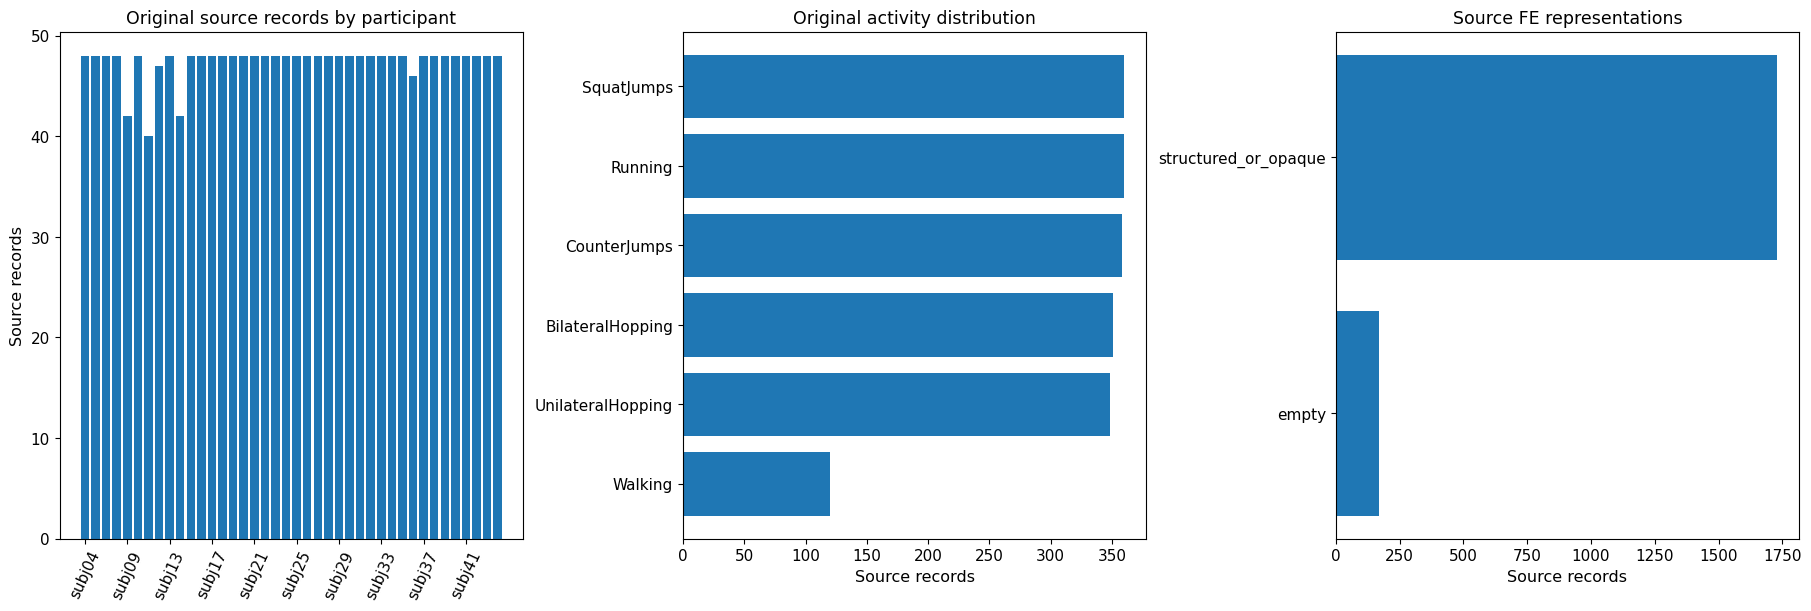

In [12]:
# ================= 11. Consolidated Research Coverage Figure =================

# ---------- 1. Prepare Participant and FE Representation Summaries -----------
subject_counts = records.groupby("subject_id").size().sort_index()
fe_counts = records["fe_representation"].value_counts()

# ---------- 2. Plot Three Complementary Source-Level Distributions -----------
fig, axes = plt.subplots(1, 3, figsize=(18, 6), constrained_layout=True)
positions = list(range(len(subject_counts)))
axes[0].bar(positions, subject_counts.values)
axes[0].set_xticks(positions[::4])
axes[0].set_xticklabels(subject_counts.index[::4], rotation=65)
axes[0].set_title("Original source records by participant")
axes[0].set_ylabel("Source records")
axes[1].barh(activity_counts.index, activity_counts.values)
axes[1].invert_yaxis()
axes[1].set_title("Original activity distribution")
axes[1].set_xlabel("Source records")
axes[2].barh(fe_counts.index, fe_counts.values)
axes[2].invert_yaxis()
axes[2].set_title("Source FE representations")
axes[2].set_xlabel("Source records")
save_figure(fig, output_dir / "01_combined_source_coverage.png")
plt.show()


**12. Integrated Source and Trial Quality Gate**

Combine the source-integrity checks of historical Notebook 01 and the record/participant checks of Notebook 02. Use the archived Stage 03 source fingerprint and, when both legacy 01/02 JSONs are available, compare their SHA256 and participant records in read-only mode. The resulting report retains the published source metadata, per-file digests, subject agreement and trial registry, without claiming numeric FE modelling readiness.


In [13]:
# =============== 12. Integrated Source and Trial Quality Gate ================

# ---------------- 1. Source, Subject and Trial Quality Checks ----------------
assert int(target_table["empty"].sum()) == 168
assert int(audit_table["record_count"].sum()) == 1897
assert len(records) == 1897 and records["local_record_key"].is_unique
assert records["task"].nunique() == 6
baseline_path = historical_output_dir / "03_numeric_recovery_quality_gate.json"
if not baseline_path.is_file():
    raise FileNotFoundError("Archived Stage 03 source fingerprint is required.")
baseline = json.loads(baseline_path.read_text(encoding="utf-8"))
assert baseline["data_integrity_gate"] == "PASSED"
assert baseline["figshare_article"] == ARTICLE_ID
assert baseline["dataset_version"] == ARTICLE_VERSION
assert baseline["archive_sha256"] == archive_hashes["sha256"]
assert baseline["participants"] == 40
assert baseline["source_records"] == 1897

assert ARTICLE_ID == 30225739 and ARTICLE_VERSION == 13
assert workbook_audit["id_alignment_passed"]
assert trial_summary["source_participants"] == 40
assert trial_summary["source_records"] == 1897
assert records["local_record_key"].is_unique
assert set(records["subject_id"]) == set(mat_ids)
assert int(sum(trial_summary["fe_encoding_counts"].values())) == len(records)
assert int(sum(trial_summary["imu_encoding_counts"].values())) == len(records)

fe_numeric_count = trial_summary["fe_encoding_counts"].get(
    "numeric_candidate", 0
)

# ----------- 2. Verify Both Historical SHA256 and Record Manifests -----------
historical_names = [
    "01_source_provenance_and_quality_gate.json",
    "02_record_provenance_and_quality_gate.json",
]
historical_paths = [historical_output_dir / name for name in historical_names]
available = [path.is_file() for path in historical_paths]
if any(available) and not all(available):
    raise FileNotFoundError(
        "Only one of the original 01/02 Quality Gates is available."
    )
legacy_gate_comparison = all(available)
if legacy_gate_comparison:
    prior_01 = json.loads(historical_paths[0].read_text(encoding="utf-8"))
    prior_02 = json.loads(historical_paths[1].read_text(encoding="utf-8"))
    assert prior_01["archive_sha256"] == archive_hashes["sha256"]
    assert prior_02["archive_sha256"] == archive_hashes["sha256"]
    assert prior_01["participant_workbook_sha256"] == workbook_hashes["sha256"]
    assert prior_02["participant_workbook_sha256"] == workbook_hashes["sha256"]
    assert prior_01["per_file_sha256"] == dict(zip(
        audit_table["source_file"], audit_table["source_sha256"]
    ))
    assert prior_01["fe_representation_counts"] == {
        name: int(target_table[name].sum()) for name in status_cols
    }
    assert prior_02["source_record_summary"] == trial_summary
    assert prior_02["participant_workbook_audit"] == workbook_audit
else:
    print("Original 01/02 Quality Gate files are not tracked here.")
    print("Dataset SHA256 verified against archived Stage 03 evidence.")
    print("Historical per-file comparison: NOT PERFORMED")

assert trial_summary["readable_updated_trial_ids"] == 1897
assert trial_summary["duplicate_subject_trial_ids"] == 0
assert workbook_audit["unique_participant_ids"] == 40
assert workbook_audit["duplicate_ids"] == 0
assert int(target_table["matlab_object_unresolved"].sum()) == 1729
assert sum(trial_summary["imu_encoding_counts"].values()) == 1897
assert audit_table["source_sha256"].str.fullmatch(r"[0-9a-f]{64}").all()

# ------- 3. Preserve Original Source and Trial Provenance in One JSON --------
provenance = {
    "source_article_id": ARTICLE_ID,
    "version": ARTICLE_VERSION,
    "publication_title": metadata["title"],
    "publication_doi": metadata["doi"],
    "publication_license": metadata["license"],
    "published_archive_file_id": metadata["archive_file_id"],
    "published_archive_size_bytes": metadata["archive_size_bytes"],
    "published_archive_md5": metadata["archive_published_md5"],
    "archive_sha256": archive_hashes["sha256"],
    "archive_md5": archive_hashes["md5"],
    "participant_workbook_sha256": workbook_hashes["sha256"],
    "participant_workbook_audit": workbook_audit,
    "source_record_summary": trial_summary,
    "per_file_sha256": dict(zip(
        audit_table["source_file"], audit_table["source_sha256"]
    )),
    "fe_representation_counts": {
        name: int(target_table[name].sum()) for name in status_cols
    },
    "source_and_trial_quality_gate": "PASSED",
    "source_fingerprint_checked_against": baseline_path.name,
    "original_01_02_gate_pair_available": legacy_gate_comparison,
    "legacy_quality_gate_comparison_performed": legacy_gate_comparison,
    "numeric_fe_waveforms_verified_here": False,
    "physical_units_verified_here": False,
    "imu_fe_timebase_verified_here": False,
    "model_ready_here": False,
    "model_training_performed": False,
}
(output_dir / "01_consolidated_source_and_trial_quality_gate.json").write_text(
    json.dumps(provenance, indent=2, ensure_ascii=False) + "\n",
    encoding="utf-8"
)
print("CONSOLIDATED 01 | SOURCE AND TRIAL QUALITY GATE: PASSED")
print("Historical research outputs overwritten: NO")
print("Regression model-readiness established: NO")

# ------------- 4. Package Research Outputs for Manual Retrieval --------------
download_outputs_from_colab(folder="biomechanical_load_estimation/output", stage="01")


FileNotFoundError: Archived Stage 03 source fingerprint is required.

**13. Research Interpretation and Next Stage Boundary**

**Research contribution:** A coherent, source-verified workflow for the official six-activity Essex dataset: archive and licence provenance, 40 authentic participant identifiers, original source MAT structures, 1,897 traceable movement records, original FE representation and missingness, source-specific coverage and two historically recorded Quality Gates.

**Historic findings to reconfirm after revision:** 1,897 readable original trial IDs with no duplicate participant–trial combinations; 1,897 IMU field representations, 1,729 opaque/structured FE representations and 168 source-empty FE fields. The previous run recorded PASSED, but the revised Quality Gate requires re-execution to verify its additional archived-fingerprint checks.

**Scientific limitations:** Verified source integrity and original field representation are not the same as numerical FE waveform recovery, physical unit verification, time alignment, valid independent Test splitting or clinical generalisation.

**Evidence protection:** The original research files and executed notebooks remain unchanged. New files are saved directly in the project `output/` directory. Where historical Stage 01 filenames exist, this notebook uses distinct `01_dataset_*` output names. The standard Stage 01 download command is now the final step in the integrated Quality Gate; no separate packaging cell is required.

**Next independent topic:** MATLAB object decoding and numerical signal recovery, integrating historical Stages 03–05. Consolidated Notebook 02 is available as an unexecuted review candidate; the original decoding-method notebooks remain preserved until its scientific evidence is verified.
